# Data Visualization

In [3]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt

## Model Comparison

Avg. Acc on training sets

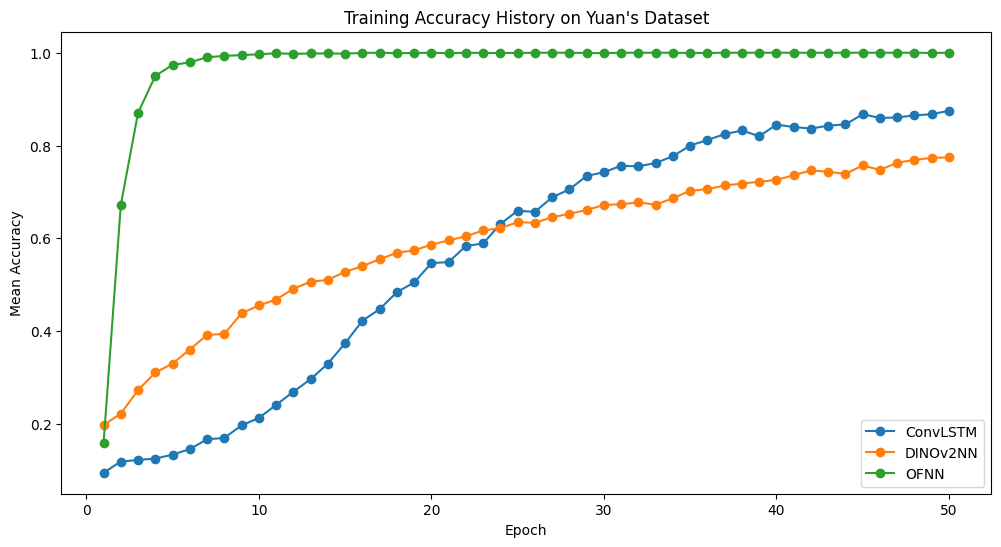

{'ConvLSTM': 0.8675000035762787,
 'DINOv2NN': 0.7735,
 'OFNN': 0.9995000004768372}

In [21]:
# Function to read CSV files, calculate column means, and plot the data
def read_and_plot(file_paths, labels, title):
    plt.figure(figsize=(12, 6))
    final_mean = {}
    # Loop through each file, calculate the mean, and plot it
    for i, file in enumerate(file_paths):
        # Read the CSV file into a pandas DataFrame
        df = pd.read_csv(file, header=None)
        
        # The first column is the label, ignore it for calculation
        data = df.iloc[:, 1:]
        
        # Calculate the mean of each column
        column_means = data.mean(axis=0)
        
        # Plot the mean values as a line
        plt.plot(column_means, marker='o', label=labels[i])
        final_mean[labels[i]] = column_means[len(column_means)-1]   # Store the final mean value for each model
    # Add title and labels
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Mean Accuracy')
    
    # Show legend to distinguish between the lines
    plt.legend()
    
    # Display the plot
    plt.show()
    return final_mean

# File paths and corresponding labels
file_paths = [
    'metrics\Comp_Model_Aug_10_final_yuan_ConvLSTM_train_accuracy_history.csv',
    'metrics\Comp_Model_Aug_10_final_yuan_DINOv2NN_train_accuracy_history.csv',
    'metrics\Comp_Model_Aug_10_final_yuan_OpticalFlowNN_train_accuracy_history.csv'
]


labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Training Accuracy History on Yuan's Dataset")

Avg.Acc on validation set

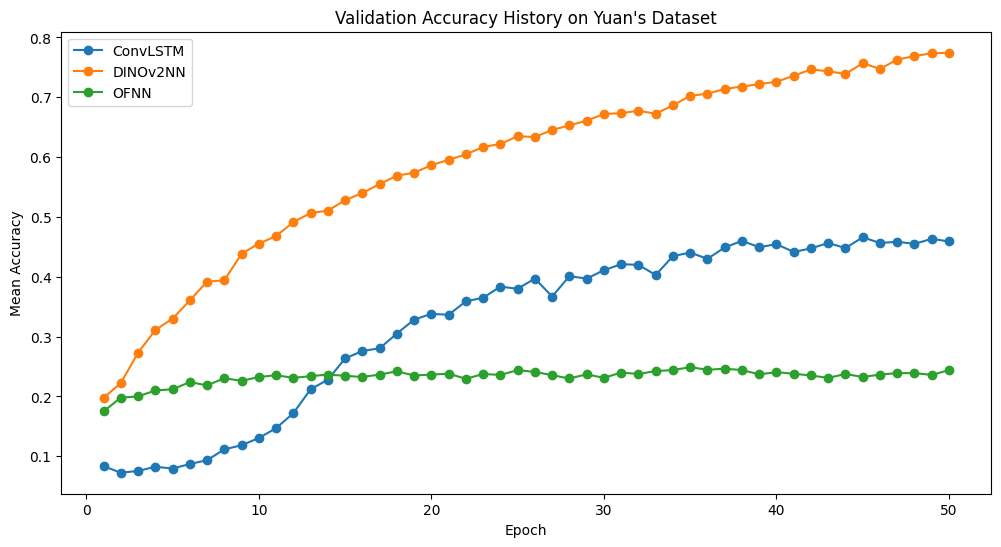

{'ConvLSTM': 0.46349999770522116,
 'DINOv2NN': 0.7735,
 'OFNN': 0.23600000195205212}

In [22]:
# File paths and corresponding labels
file_paths = [
    'metrics\Comp_Model_Aug_10_final_yuan_ConvLSTM_val_accuracy_history.csv',
    'metrics\Comp_Model_Aug_10_final_yuan_DINOv2NN_val_accuracy_history.csv',
    'metrics\Comp_Model_Aug_10_final_yuan_OpticalFlowNN_val_accuracy_history.csv'
]


labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Validation Accuracy History on Yuan's Dataset")

## Adaptive Sampling 

TBD

## Domain Expansion

C:\Users\bnkrg\AppData\Local\Temp\ipykernel_2904\4232625243.py:27: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x_smooth, y_smooth, label=row[0])


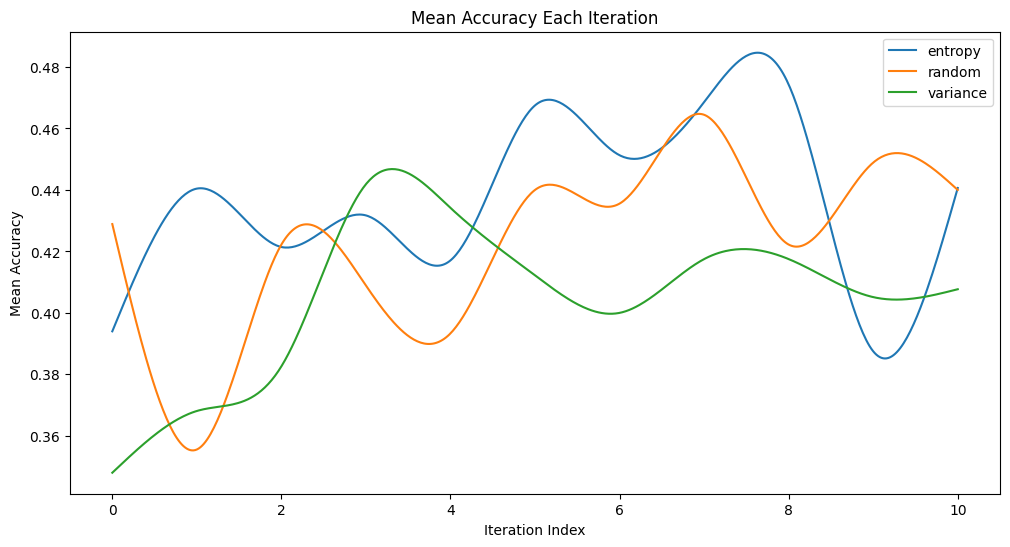

In [8]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import CubicSpline

# Function to interpolate using cubic splines and plot each row as a separate curve
def read_and_plot_smoothed_curves(csv_file):
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(csv_file)
    
    plt.figure(figsize=(12, 6))
    
    for index, row in df.iterrows():
        # Extract iteration indices and values
        x = np.arange(len(row[1:]))  # x-coordinates (iteration indices)
        y = row[1:].values          # y-coordinates (values)
        
        # Perform cubic spline interpolation
        cs = CubicSpline(x, y, bc_type='natural')
        
        # Generate a smooth curve
        x_smooth = np.linspace(x.min(), x.max(), 500)  # 500 points for smooth curve
        y_smooth = cs(x_smooth)
        
        # Plot the smooth curve
        plt.plot(x_smooth, y_smooth, label=row[0])
    
    plt.title('Mean Accuracy Each Iteration')
    plt.xlabel('Iteration Index')
    plt.ylabel('Mean Accuracy')
    plt.legend()
    plt.show()

# Example usage: replace 'data.csv' with your actual CSV file path
read_and_plot_smoothed_curves('domain_expansion.csv')
